# 01 · Data overview
Counts from `reports/eda.json` (written by `python services/ai/evaluate.py --all`).

In [1]:
import json
from pathlib import Path

import pandas as pd

R = Path("../reports")  # the only directory read (scripts/run_notebooks.py --check-reads-only)


def load(name):
    return json.loads((R / name).read_text(encoding="utf-8"))
eda = load("eda.json")
print("artifact", eda["artifact_version"], eda["sha"], "generated", eda["generated_at"])
off = eda["official"]
print({k: off[k] for k in ("rows", "distinct_texts", "scenarios", "groups")}, off["wrappers"])

artifact v1 a8e2f1e58da5 generated 2026-11-06T18:06:47+00:00
{'rows': 432, 'distinct_texts': 42, 'scenarios': 42, 'groups': 30} {'distinct_prefixes': 16, 'distinct_suffixes': 2, 'with_prefix': 348, 'with_suffix': 42}


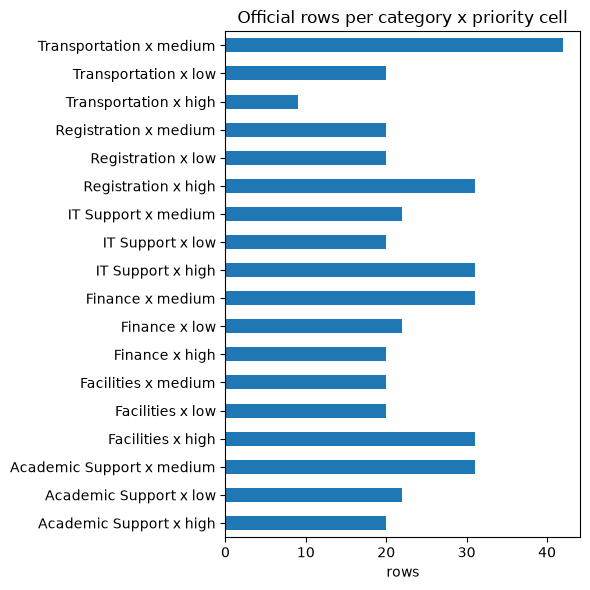

In [2]:
import matplotlib.pyplot as plt

cells = pd.Series(off["by_cell"]).sort_index()
ax = cells.plot.barh(figsize=(6, 6), title="Official rows per category x priority cell")
ax.set_xlabel("rows")
plt.tight_layout()
plt.show()

In [3]:
aug = pd.DataFrame(eda["augmented"]).T[["rows", "groups", "reviewed"]]
aug["unreviewed"] = aug["rows"] - aug["reviewed"]
display(aug)
display(pd.DataFrame({"our_test by set": pd.Series(eda["our_test"]["by_set"]),
                      "our_test by lang": pd.Series(eda["our_test"]["by_lang"])}))

,rows,groups,reviewed,unreviewed
arabizi.csv,30,15,0,30
arabizi_from_official.csv,126,30,0,126
new_scenarios.csv,390,78,0,390
paraphrases.csv,64,27,0,64
translations.csv,17,16,0,17


,our_test by set,our_test by lang
ar,NaN,132.0
arabizi,NaN,91.0
en,NaN,173.0
set1,72.0,NaN
set2,72.0,NaN
set3,108.0,NaN
set4,144.0,NaN
